# dense_embedding_compare

본 노트북은 `dense_embedding_exp1`, `dense_embedding_exp2`, `dense_embedding_exp3`에서 생성한 입력 데이터를 한 번에 불러와 dense embedding cosine similarity를 계산하고, 실제 ESG 등급과의 관련성을 비교한다.

## 비교 대상

- exp1: 기준 문장 ↔ 기업·연도별 문서 전체
- exp2: 기준 문장 ↔ 기업·연도·섹션별 텍스트
- exp3: 기준 문장 ↔ 기업·연도·섹션·문장별 텍스트

## 비교 기준

- E 기준 문장 cosine similarity
- S 기준 문장 cosine similarity
- G 기준 문장 cosine similarity
- E/S/G 종합 similarity
- 실제 ESG 등급과의 Spearman 상관계수
- ESG 우수 그룹과 비우수 그룹의 평균 차이
- 시각화 결과

# 1. 라이브러리 및 경로 설정

- exp1, exp2, exp3 입력 파일을 불러오기 위한 경로를 설정한다.
- dense embedding 모델과 통계분석, 시각화에 필요한 라이브러리를 불러온다.

In [1]:
# ============================================================
# 1. 라이브러리 및 경로 설정
# ============================================================

import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, ttest_ind, mannwhitneyu

warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "data").exists():
            return candidate
    return Path.cwd()


PROJECT_ROOT = find_project_root()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ANALYSIS_DIR = PROCESSED_DIR / "analysis"
DENSE_DIR = ANALYSIS_DIR / "dense_embedding_compare"

EXP1_PATH = DENSE_DIR / "dense_embedding_exp1_document_unit.csv"
EXP2_PATH = DENSE_DIR / "dense_embedding_exp2_section_unit.csv"
EXP3_PATH = DENSE_DIR / "dense_embedding_exp3_sentence_unit.csv"

OUTPUT_DIR = DENSE_DIR / "comparison_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DENSE_DIR:", DENSE_DIR)
print("EXP1_PATH:", EXP1_PATH)
print("EXP2_PATH:", EXP2_PATH)
print("EXP3_PATH:", EXP3_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR)

PROJECT_ROOT: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final
DENSE_DIR: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare
EXP1_PATH: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\dense_embedding_exp1_document_unit.csv
EXP2_PATH: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\dense_embedding_exp2_section_unit.csv
EXP3_PATH: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\dense_embedding_exp3_sentence_unit.csv
OUTPUT_DIR: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results


# 2. Dense Embedding 모델 불러오기

- 한국어 문장 의미 유사도 계산에 사용할 sentence-transformers 모델을 불러온다.
- 모든 exp에 동일한 모델을 적용한다.
- 모델을 동일하게 고정해야 exp1, exp2, exp3 결과를 공정하게 비교할 수 있다.

In [2]:
# ============================================================
# 2. Dense Embedding 모델 불러오기
# ============================================================

# 설치가 안 되어 있으면 터미널 또는 노트북에서 먼저 실행:
# !pip install sentence-transformers

from sentence_transformers import SentenceTransformer

MODEL_NAME = "jhgan/ko-sroberta-multitask"
# 대안:
# MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
# MODEL_NAME = "snunlp/KR-SBERT-V40K-klueNLI-augSTS"

model = SentenceTransformer(MODEL_NAME)

print("사용 모델:", MODEL_NAME)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4740.43it/s]


사용 모델: jhgan/ko-sroberta-multitask


# 3. E/S/G 기준 문장 설정

- K-ESG 주요 평가 항목과 seed dictionary의 핵심 단어를 반영하여 기준 문장을 설정한다.
- 각 공시 텍스트가 E/S/G 기준 문장과 얼마나 유사한지 cosine similarity로 계산한다.

In [3]:
# ============================================================
# 3. E/S/G 기준 문장 설정
# ============================================================

reference_sentences = {
    "E": [
        "기업은 환경경영 목표와 추진체계를 수립하고 환경 관련 성과를 체계적으로 관리한다.",
        "기업은 온실가스 배출량과 탄소배출을 측정하고 감축 목표와 실행 계획을 수립한다.",
        "기업은 에너지 사용량을 관리하고 에너지 효율 개선과 재생에너지 사용 확대를 추진한다.",
        "기업은 원부자재 사용량, 폐기물 발생량, 재활용률을 관리하여 자원 사용의 효율성을 높인다.",
        "기업은 환경 법규와 환경 인허가를 준수하고 환경규제 위반 및 환경 리스크를 관리한다.",
    ],
    "S": [
        "기업은 임직원의 산업안전과 보건을 보호하기 위한 안전보건 관리체계를 운영한다.",
        "기업은 임직원의 고용 안정, 근로환경 개선, 복리후생 확대를 위해 노력한다.",
        "기업은 임직원과 이해관계자의 인권을 보호하고 다양성과 차별 방지를 위한 정책을 운영한다.",
        "기업은 협력사와 공급망의 사회적 책임을 관리하고 공정한 거래와 상생협력을 추진한다.",
        "기업은 고객 안전, 소비자 보호, 지역사회 기여 등 이해관계자에 대한 사회적 책임을 이행한다.",
    ],
    "G": [
        "기업은 이사회 중심의 투명한 의사결정 체계를 구축하고 이사회 운영의 전문성과 책임성을 강화한다.",
        "기업은 사외이사의 독립성과 전문성을 확보하여 이사회 독립성을 강화한다.",
        "기업은 감사위원회와 내부통제 제도를 통해 경영 감시와 리스크 관리 체계를 강화한다.",
        "기업은 윤리경영과 준법경영 체계를 구축하고 부패방지와 컴플라이언스 관리를 수행한다.",
        "기업은 주주권리를 보호하고 경영 정보를 투명하게 공개하여 이해관계자의 신뢰를 높인다.",
    ],
}

for dim, refs in reference_sentences.items():
    print(dim, "기준 문장 수:", len(refs))

E 기준 문장 수: 5
S 기준 문장 수: 5
G 기준 문장 수: 5


# 4. 공통 함수 정의

- 텍스트를 dense embedding 벡터로 변환한다.
- 기준 문장 벡터와 공시 텍스트 벡터 간 cosine similarity를 계산한다.
- E/S/G별 최대 유사도와 평균 유사도를 생성한다.

**점수 해석**

- `_max`: 해당 차원의 기준 문장 중 가장 유사한 문장과의 유사도
- `_mean`: 해당 차원의 기준 문장 전체와의 평균 유사도
- `total_max`: E/S/G의 max 점수를 합산한 종합 점수
- `total_mean`: E/S/G의 mean 점수를 합산한 종합 점수

In [4]:
# ============================================================
# 4. 공통 함수 정의
# ============================================================

def encode_texts(texts, batch_size=32):
    """
    텍스트 리스트를 dense embedding으로 변환한다.
    normalize_embeddings=True로 설정하면 dot product가 cosine similarity와 같아진다.
    """
    texts = ["" if pd.isna(t) else str(t) for t in texts]

    embeddings = model.encode(
        texts,
        batch_size=batch_size,
        show_progress_bar=True,
        normalize_embeddings=True,
    )

    return np.asarray(embeddings)


def build_reference_embeddings(reference_sentences):
    """
    E/S/G 기준 문장을 embedding으로 변환한다.
    """
    ref_embeddings = {}

    for dim, refs in reference_sentences.items():
        ref_embeddings[dim] = encode_texts(refs, batch_size=16)

    return ref_embeddings


def add_dense_similarity_scores(df, text_col, prefix, ref_embeddings, batch_size=32):
    """
    입력 데이터프레임의 text_col에 대해 E/S/G 기준 문장과의 cosine similarity를 계산한다.
    """
    result_df = df.copy()

    texts = result_df[text_col].fillna("").astype(str).tolist()
    doc_embeddings = encode_texts(texts, batch_size=batch_size)

    for dim in ["E", "S", "G"]:
        ref_emb = ref_embeddings[dim]

        # normalized embedding이므로 dot product = cosine similarity
        sim_matrix = doc_embeddings @ ref_emb.T

        result_df[f"{prefix}_{dim}_max"] = sim_matrix.max(axis=1)
        result_df[f"{prefix}_{dim}_mean"] = sim_matrix.mean(axis=1)

    result_df[f"{prefix}_total_max"] = (
        result_df[f"{prefix}_E_max"]
        + result_df[f"{prefix}_S_max"]
        + result_df[f"{prefix}_G_max"]
    )

    result_df[f"{prefix}_total_mean"] = (
        result_df[f"{prefix}_E_mean"]
        + result_df[f"{prefix}_S_mean"]
        + result_df[f"{prefix}_G_mean"]
    )

    max_cols = [
        f"{prefix}_E_max",
        f"{prefix}_S_max",
        f"{prefix}_G_max",
    ]

    result_df[f"{prefix}_dominant_dim"] = (
        result_df[max_cols]
        .idxmax(axis=1)
        .str.replace(f"{prefix}_", "", regex=False)
        .str.replace("_max", "", regex=False)
    )

    return result_df


def topk_mean(series, k=5):
    """
    상위 k개 값의 평균을 계산한다.
    """
    series = pd.Series(series).dropna()

    if len(series) == 0:
        return np.nan

    return series.nlargest(min(k, len(series))).mean()


ref_embeddings = build_reference_embeddings(reference_sentences)

print("기준 문장 embedding 생성 완료")

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  8.30it/s]

기준 문장 embedding 생성 완료


# 5. exp1 데이터 불러오기 및 문서 단위 유사도 계산

- exp1은 기업·연도별 전체 문서를 기준 문장과 비교한다.
- 한 기업·연도당 하나의 점수가 생성된다.

In [5]:
# ============================================================
# 5. exp1 데이터 불러오기 및 문서 단위 유사도 계산
# ============================================================

exp1_df = pd.read_csv(EXP1_PATH, dtype={"stock_code": str})

print("exp1 데이터 크기:", exp1_df.shape)
print(exp1_df.columns.tolist())

required_col = "exp1_document_text"

if required_col not in exp1_df.columns:
    raise ValueError(f"exp1 데이터에 {required_col} 컬럼이 없습니다.")

exp1_scored = add_dense_similarity_scores(
    df=exp1_df,
    text_col="exp1_document_text",
    prefix="exp1",
    ref_embeddings=ref_embeddings,
    batch_size=16,
)

exp1_result = exp1_scored.copy()

exp1_result["experiment"] = "exp1_document_unit"
exp1_result["unit_type"] = "document"
exp1_result["score_E"] = exp1_result["exp1_E_max"]
exp1_result["score_S"] = exp1_result["exp1_S_max"]
exp1_result["score_G"] = exp1_result["exp1_G_max"]
exp1_result["score_total"] = exp1_result["exp1_total_max"]

print("exp1 scoring 완료")
display(
    exp1_result[
        [
            "analysis_unit",
            "company_name" if "company_name" in exp1_result.columns else "stock_code",
            "fiscal_year",
            "esg_grade",
            "score_E",
            "score_S",
            "score_G",
            "score_total",
        ]
    ].head()
)

exp1 데이터 크기: (176, 14)
['analysis_unit', 'stock_code', 'company_name', 'fiscal_year', 'esg_year', 'esg_grade', 'esg_grade_num', 'included_sections', 'section_count', 'document_text_chars', 'document_text_rows', 'raw_document_text', 'exp1_document_text', 'exp1_document_text_chars']


Batches: 100%|██████████| 11/11 [01:26<00:00,  7.90s/it]


exp1 scoring 완료


,analysis_unit,company_name,fiscal_year,esg_grade,score_E,score_S,score_G,score_total
0,000020x2023,동화약품,2023,C,0.350940,0.349601,0.498880,1.199420
1,000020x2024,동화약품,2024,C,0.372824,0.388960,0.503313,1.265097
2,000050x2022,경방,2022,C,0.351881,0.342640,0.490117,1.184638
3,000050x2023,경방,2023,C,0.326163,0.338822,0.537503,1.202488
4,000050x2024,경방,2024,C,0.361480,0.397072,0.545335,1.303887


# 6. exp2 데이터 불러오기 및 섹션 단위 유사도 계산

- exp2는 기업·연도·섹션별 텍스트를 기준 문장과 비교한다.
- 이후 기업·연도 단위로 다시 집계한다.
- 집계 방식은 두 가지를 사용한다.

1. `section_mean`: 전체 섹션에 걸친 평균적인 ESG 유사도 
2. `section_max`: 특정 핵심 섹션에서 강하게 나타난 ESG 유사도

In [6]:
# ============================================================
# 6. exp2 데이터 불러오기 및 섹션 단위 유사도 계산
# ============================================================

exp2_df = pd.read_csv(EXP2_PATH, dtype={"stock_code": str})

print("exp2 데이터 크기:", exp2_df.shape)
print(exp2_df.columns.tolist())

required_col = "exp2_section_text"

if required_col not in exp2_df.columns:
    raise ValueError(f"exp2 데이터에 {required_col} 컬럼이 없습니다.")

exp2_scored = add_dense_similarity_scores(
    df=exp2_df,
    text_col="exp2_section_text",
    prefix="exp2",
    ref_embeddings=ref_embeddings,
    batch_size=16,
)

# 섹션별 점수 저장
exp2_section_score_path = OUTPUT_DIR / "exp2_section_dense_scores.csv"
exp2_scored.to_csv(exp2_section_score_path, index=False, encoding="utf-8-sig")
print("exp2 섹션별 점수 저장:", exp2_section_score_path)


# 기업-연도 단위 집계
base_keys = [
    "analysis_unit",
    "stock_code",
    "fiscal_year",
    "esg_year",
    "esg_grade",
    "esg_grade_num",
]

for c in ["company_name", "회사이름"]:
    if c in exp2_scored.columns and c not in base_keys:
        base_keys.append(c)

agg_dict = {}

for dim in ["E", "S", "G"]:
    agg_dict[f"exp2_{dim}_section_mean"] = (f"exp2_{dim}_max", "mean")
    agg_dict[f"exp2_{dim}_section_max"] = (f"exp2_{dim}_max", "max")

agg_dict["exp2_total_section_mean"] = ("exp2_total_max", "mean")
agg_dict["exp2_total_section_max"] = ("exp2_total_max", "max")
agg_dict["exp2_section_count"] = ("section_clean", "nunique")

exp2_agg = (
    exp2_scored
    .groupby(base_keys, as_index=False)
    .agg(**agg_dict)
)

# total이 가장 높았던 대표 섹션 확인
idx_best_section = (
    exp2_scored
    .groupby("analysis_unit")["exp2_total_max"]
    .idxmax()
)

best_section_df = exp2_scored.loc[
    idx_best_section,
    ["analysis_unit", "section_clean", "exp2_total_max"]
].rename(columns={
    "section_clean": "exp2_best_section",
    "exp2_total_max": "exp2_best_section_total_score"
})

exp2_agg = pd.merge(
    exp2_agg,
    best_section_df,
    on="analysis_unit",
    how="left"
)

# 비교용 long 결과 2개 생성: section_mean, section_max
exp2_mean_result = exp2_agg.copy()
exp2_mean_result["experiment"] = "exp2_section_mean"
exp2_mean_result["unit_type"] = "section_mean"
exp2_mean_result["score_E"] = exp2_mean_result["exp2_E_section_mean"]
exp2_mean_result["score_S"] = exp2_mean_result["exp2_S_section_mean"]
exp2_mean_result["score_G"] = exp2_mean_result["exp2_G_section_mean"]
exp2_mean_result["score_total"] = exp2_mean_result["exp2_total_section_mean"]

exp2_max_result = exp2_agg.copy()
exp2_max_result["experiment"] = "exp2_section_max"
exp2_max_result["unit_type"] = "section_max"
exp2_max_result["score_E"] = exp2_max_result["exp2_E_section_max"]
exp2_max_result["score_S"] = exp2_max_result["exp2_S_section_max"]
exp2_max_result["score_G"] = exp2_max_result["exp2_G_section_max"]
exp2_max_result["score_total"] = exp2_max_result["exp2_total_section_max"]

print("exp2 scoring 및 집계 완료")
display(
    exp2_agg[
        [
            "analysis_unit",
            "exp2_total_section_mean",
            "exp2_total_section_max",
            "exp2_best_section",
        ]
    ].head()
)

exp2 데이터 크기: (3134, 16)
['section_analysis_unit', 'analysis_unit', 'stock_code', 'company_name', 'fiscal_year', 'esg_year', 'esg_grade', 'esg_grade_num', 'section_roman', 'section_clean', 'section_order', 'matched_heading', 'section_text_chars', 'raw_section_text', 'exp2_section_text', 'exp2_section_text_chars']


Batches: 100%|██████████| 196/196 [05:46<00:00,  1.77s/it]


exp2 섹션별 점수 저장: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\exp2_section_dense_scores.csv
exp2 scoring 및 집계 완료


,analysis_unit,exp2_total_section_mean,exp2_total_section_max,exp2_best_section
0,000020x2022,1.288022,1.453459,II. 사업의 내용
1,000020x2023,1.297444,1.453459,II. 사업의 내용
2,000020x2024,1.289964,1.453459,II. 사업의 내용
3,000040x2022,1.125211,1.315034,VIII. 임원 및 직원 등에 관한 사항
4,000040x2023,1.181835,1.521662,VI. 이사회 등 회사의 기관에 관한 사항


# 7. exp3 데이터 불러오기 및 문장 단위 유사도 계산

- exp3는 기업·연도·섹션·문장별 텍스트를 기준 문장과 비교한다.
- 이후 기업·연도 단위로 다시 집계한다.
- 집계 방식은 세 가지를 사용한다.

1. `sentence_mean`: 보고서 전체 문장의 평균적인 ESG 유사도
2. `sentence_max`: 가장 ESG 기준에 가까운 핵심 문장 1개
3. `sentence_top5_mean`: 우연히 높은 문장 1개에 과도하게 의존하지 않기 위한 상위 5개 평균

*exp3는 문장 단위 embedding 계산으로 실행 시간이 매우 길어, 기업-연도별 최대 300개 문장만 사용하고 중복·과도한 길이의 문장을 제거하는 제한 버전으로 대체하였다.

In [16]:
# ============================================================
# 7. exp3 데이터 불러오기 및 문장 단위 유사도 계산
#    - 기업-연도별 최대 300문장 제한 버전
# ============================================================

# 제한 버전 결과 파일명
exp3_sentence_score_path = OUTPUT_DIR / "exp3_sentence_dense_scores_limited_300.csv"

MAX_SENTENCES_PER_UNIT = 300
MIN_SENTENCE_CHARS = 30
MAX_SENTENCE_CHARS = 800

# ------------------------------------------------------------
# 0. topk_mean 함수가 없을 경우 대비
# ------------------------------------------------------------

def topk_mean(series, k=5):
    series = pd.Series(series).dropna()

    if len(series) == 0:
        return np.nan

    return series.nlargest(min(k, len(series))).mean()


# ------------------------------------------------------------
# 1. 이미 계산된 제한 버전 결과가 있으면 바로 불러오기
# ------------------------------------------------------------

if exp3_sentence_score_path.exists():
    print("이미 계산된 exp3 제한 버전 점수 파일이 있어 다시 계산하지 않고 불러옵니다.")
    exp3_scored = pd.read_csv(exp3_sentence_score_path, dtype={"stock_code": str})

else:
    # ------------------------------------------------------------
    # 2. exp3 원본 데이터 불러오기
    # ------------------------------------------------------------

    exp3_df = pd.read_csv(EXP3_PATH, dtype={"stock_code": str})

    print("exp3 원본 데이터 크기:", exp3_df.shape)
    print("exp3 컬럼:")
    print(exp3_df.columns.tolist())

    required_col = "exp3_sentence_text"

    if required_col not in exp3_df.columns:
        raise ValueError(f"exp3 데이터에 {required_col} 컬럼이 없습니다.")

    if "analysis_unit" not in exp3_df.columns:
        raise ValueError("exp3 데이터에 analysis_unit 컬럼이 없습니다.")

    # ------------------------------------------------------------
    # 3. 문장 기본 정리
    # ------------------------------------------------------------

    exp3_df[required_col] = exp3_df[required_col].fillna("").astype(str)

    exp3_df["exp3_sentence_text_chars"] = (
        exp3_df[required_col]
        .str.len()
    )

    print("문장 수 제한 전:", exp3_df.shape)

    # ------------------------------------------------------------
    # 4. 너무 짧거나 너무 긴 문장 제거
    # ------------------------------------------------------------

    exp3_df = exp3_df[
        exp3_df["exp3_sentence_text_chars"].between(
            MIN_SENTENCE_CHARS,
            MAX_SENTENCE_CHARS
        )
    ].copy()

    print(f"길이 필터 후 ({MIN_SENTENCE_CHARS}~{MAX_SENTENCE_CHARS}자):", exp3_df.shape)

    # ------------------------------------------------------------
    # 5. 완전 중복 문장 제거
    # 같은 기업-연도 안에서 동일 문장이 반복되면 하나만 남김
    # ------------------------------------------------------------

    before = len(exp3_df)

    exp3_df = exp3_df.drop_duplicates(
        subset=["analysis_unit", "exp3_sentence_text"]
    ).copy()

    after = len(exp3_df)

    print(f"중복 문장 제거: {before} → {after}")

    # ------------------------------------------------------------
    # 6. 기업-연도별 최대 300문장 제한
    # 긴 문장일수록 정보량이 많다고 보고 우선 유지
    # ------------------------------------------------------------

    exp3_df = (
        exp3_df
        .sort_values(
            ["analysis_unit", "exp3_sentence_text_chars"],
            ascending=[True, False]
        )
        .groupby("analysis_unit", as_index=False)
        .head(MAX_SENTENCES_PER_UNIT)
        .copy()
    )

    print(f"기업-연도별 최대 {MAX_SENTENCES_PER_UNIT}개 문장 제한 후:", exp3_df.shape)

    print("\n기업-연도별 문장 수 요약:")
    print(
        exp3_df
        .groupby("analysis_unit")["exp3_sentence_text"]
        .count()
        .describe()
    )

    print("\n섹션별 문장 수:")
    if "section_clean" in exp3_df.columns:
        print(exp3_df["section_clean"].value_counts())

    # ------------------------------------------------------------
    # 7. Dense embedding cosine similarity 계산
    # ------------------------------------------------------------

    exp3_scored = add_dense_similarity_scores(
        df=exp3_df,
        text_col="exp3_sentence_text",
        prefix="exp3",
        ref_embeddings=ref_embeddings,
        batch_size=128,
    )

    # ------------------------------------------------------------
    # 8. 계산 결과 저장
    # 다음 실행부터는 이 파일을 바로 불러와서 시간 단축
    # ------------------------------------------------------------

    exp3_scored.to_csv(
        exp3_sentence_score_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("exp3 문장별 점수 저장:", exp3_sentence_score_path)


# ------------------------------------------------------------
# 9. 기업-연도 단위 집계
# ------------------------------------------------------------

base_keys = [
    "analysis_unit",
    "stock_code",
    "fiscal_year",
    "esg_year",
    "esg_grade",
    "esg_grade_num",
]

for c in ["company_name", "회사이름"]:
    if c in exp3_scored.columns and c not in base_keys:
        base_keys.append(c)

# 혹시 결측 등급이 있더라도 집계는 가능하게 유지
for col in base_keys:
    if col not in exp3_scored.columns:
        raise ValueError(f"exp3_scored에 필요한 컬럼이 없습니다: {col}")


agg_dict = {}

for dim in ["E", "S", "G"]:
    agg_dict[f"exp3_{dim}_sentence_mean"] = (f"exp3_{dim}_max", "mean")
    agg_dict[f"exp3_{dim}_sentence_max"] = (f"exp3_{dim}_max", "max")
    agg_dict[f"exp3_{dim}_sentence_top5_mean"] = (
        f"exp3_{dim}_max",
        lambda x: topk_mean(x, k=5)
    )

agg_dict["exp3_total_sentence_mean"] = ("exp3_total_max", "mean")
agg_dict["exp3_total_sentence_max"] = ("exp3_total_max", "max")
agg_dict["exp3_total_sentence_top5_mean"] = (
    "exp3_total_max",
    lambda x: topk_mean(x, k=5)
)
agg_dict["exp3_sentence_count"] = ("exp3_sentence_text", "count")

exp3_agg = (
    exp3_scored
    .groupby(base_keys, as_index=False)
    .agg(**agg_dict)
)

# ------------------------------------------------------------
# 10. total score가 가장 높았던 대표 문장 확인
# ------------------------------------------------------------

idx_best_sentence = (
    exp3_scored
    .groupby("analysis_unit")["exp3_total_max"]
    .idxmax()
)

best_sentence_cols = [
    "analysis_unit",
    "section_clean",
    "exp3_sentence_text",
    "exp3_total_max",
]

best_sentence_df = exp3_scored.loc[
    idx_best_sentence,
    best_sentence_cols
].rename(columns={
    "section_clean": "exp3_best_sentence_section",
    "exp3_sentence_text": "exp3_best_sentence",
    "exp3_total_max": "exp3_best_sentence_total_score",
})

exp3_agg = pd.merge(
    exp3_agg,
    best_sentence_df,
    on="analysis_unit",
    how="left"
)

# ------------------------------------------------------------
# 11. 비교용 결과 3개 생성
#     이후 8번 통합 코드에서 그대로 사용됨
# ------------------------------------------------------------

exp3_mean_result = exp3_agg.copy()
exp3_mean_result["experiment"] = "exp3_sentence_mean_limited300"
exp3_mean_result["unit_type"] = "sentence_mean"
exp3_mean_result["score_E"] = exp3_mean_result["exp3_E_sentence_mean"]
exp3_mean_result["score_S"] = exp3_mean_result["exp3_S_sentence_mean"]
exp3_mean_result["score_G"] = exp3_mean_result["exp3_G_sentence_mean"]
exp3_mean_result["score_total"] = exp3_mean_result["exp3_total_sentence_mean"]

exp3_max_result = exp3_agg.copy()
exp3_max_result["experiment"] = "exp3_sentence_max_limited300"
exp3_max_result["unit_type"] = "sentence_max"
exp3_max_result["score_E"] = exp3_max_result["exp3_E_sentence_max"]
exp3_max_result["score_S"] = exp3_max_result["exp3_S_sentence_max"]
exp3_max_result["score_G"] = exp3_max_result["exp3_G_sentence_max"]
exp3_max_result["score_total"] = exp3_max_result["exp3_total_sentence_max"]

exp3_top5_result = exp3_agg.copy()
exp3_top5_result["experiment"] = "exp3_sentence_top5_mean_limited300"
exp3_top5_result["unit_type"] = "sentence_top5_mean"
exp3_top5_result["score_E"] = exp3_top5_result["exp3_E_sentence_top5_mean"]
exp3_top5_result["score_S"] = exp3_top5_result["exp3_S_sentence_top5_mean"]
exp3_top5_result["score_G"] = exp3_top5_result["exp3_G_sentence_top5_mean"]
exp3_top5_result["score_total"] = exp3_top5_result["exp3_total_sentence_top5_mean"]

print("exp3 scoring 및 기업-연도 단위 집계 완료")

display(
    exp3_agg[
        [
            "analysis_unit",
            "exp3_sentence_count",
            "exp3_total_sentence_mean",
            "exp3_total_sentence_max",
            "exp3_total_sentence_top5_mean",
            "exp3_best_sentence_section",
            "exp3_best_sentence",
        ]
    ].head()
)

이미 계산된 exp3 제한 버전 점수 파일이 있어 다시 계산하지 않고 불러옵니다.
exp3 scoring 및 기업-연도 단위 집계 완료


,analysis_unit,exp3_sentence_count,exp3_total_sentence_mean,exp3_total_sentence_max,exp3_total_sentence_top5_mean,exp3_best_sentence_section,exp3_best_sentence
0,000020x2023,300,1.115574,1.764269,1.671407,II. 사업의 내용,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
1,000020x2024,300,1.093807,1.764269,1.664341,II. 사업의 내용,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
2,000050x2022,300,1.105580,1.768437,1.730080,II. 사업의 내용,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
3,000050x2023,300,1.102743,1.764269,1.631189,II. 사업의 내용,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
4,000050x2024,300,1.130322,1.764269,1.709780,II. 사업의 내용,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...


# 8. exp1, exp2, exp3 결과 통합

- exp1, exp2, exp3에서 생성된 기업·연도 단위 점수를 하나의 long-format 데이터로 합친다.
- 이후 동일한 방식으로 실제 ESG 등급과의 관련성을 비교한다.

In [17]:
# ============================================================
# 8. exp1, exp2, exp3 결과 통합
# ============================================================

common_cols = [
    "experiment",
    "unit_type",
    "analysis_unit",
    "stock_code",
    "fiscal_year",
    "esg_year",
    "esg_grade",
    "esg_grade_num",
    "score_E",
    "score_S",
    "score_G",
    "score_total",
]

for c in ["company_name", "회사이름"]:
    if c in exp1_result.columns and c not in common_cols:
        common_cols.insert(4, c)

comparison_df = pd.concat(
    [
        exp1_result[[c for c in common_cols if c in exp1_result.columns]],
        exp2_mean_result[[c for c in common_cols if c in exp2_mean_result.columns]],
        exp2_max_result[[c for c in common_cols if c in exp2_max_result.columns]],
        exp3_mean_result[[c for c in common_cols if c in exp3_mean_result.columns]],
        exp3_max_result[[c for c in common_cols if c in exp3_max_result.columns]],
        exp3_top5_result[[c for c in common_cols if c in exp3_top5_result.columns]],
    ],
    ignore_index=True,
)

comparison_df = comparison_df.dropna(subset=["esg_grade_num"]).copy()

# ESG 우수 그룹 기준
# 필요하면 4로 바꾸면 A 이상 기준이 됨
HIGH_ESG_THRESHOLD = 5

comparison_df["high_esg"] = np.where(
    comparison_df["esg_grade_num"] >= HIGH_ESG_THRESHOLD,
    1,
    0,
)

print("통합 비교 데이터 크기:", comparison_df.shape)
print("실험별 데이터 수:")
print(comparison_df["experiment"].value_counts())

display(comparison_df.head())

통합 비교 데이터 크기: (1466, 14)
실험별 데이터 수:
experiment
exp2_section_mean                     381
exp2_section_max                      381
exp1_document_unit                    176
exp3_sentence_mean_limited300         176
exp3_sentence_max_limited300          176
exp3_sentence_top5_mean_limited300    176
Name: count, dtype: int64


,experiment,unit_type,analysis_unit,stock_code,company_name,fiscal_year,esg_year,esg_grade,esg_grade_num,score_E,score_S,score_G,score_total,high_esg
0,exp1_document_unit,document,000020x2023,000020,동화약품,2023,2024,C,1,0.350940,0.349601,0.498880,1.199420,0
1,exp1_document_unit,document,000020x2024,000020,동화약품,2024,2025,C,1,0.372824,0.388960,0.503313,1.265097,0
2,exp1_document_unit,document,000050x2022,000050,경방,2022,2023,C,1,0.351881,0.342640,0.490117,1.184638,0
3,exp1_document_unit,document,000050x2023,000050,경방,2023,2024,C,1,0.326163,0.338822,0.537503,1.202488,0
4,exp1_document_unit,document,000050x2024,000050,경방,2024,2025,C,1,0.361480,0.397072,0.545335,1.303887,0


# 9. 실제 ESG 등급과의 Spearman 상관분석

- cosine similarity 점수와 실제 ESG 등급 숫자 간 순위상관을 계산한다.
- ESG 등급은 순서형 등급이므로 Spearman 상관계수를 우선 확인한다.
- 상관계수가 높고 p-value가 낮을수록 해당 방식이 실제 ESG 등급과 더 잘 연결된다고 해석할 수 있다.

In [18]:
# ============================================================
# 9. Spearman 상관분석
# ============================================================

score_cols = ["score_E", "score_S", "score_G", "score_total"]

spearman_rows = []

for exp_name, temp in comparison_df.groupby("experiment"):
    for score_col in score_cols:
        if temp[score_col].nunique() <= 1:
            corr, pval = np.nan, np.nan
        else:
            corr, pval = spearmanr(temp[score_col], temp["esg_grade_num"])

        spearman_rows.append({
            "experiment": exp_name,
            "score": score_col,
            "n": len(temp),
            "spearman_corr": corr,
            "p_value": pval,
            "score_mean": temp[score_col].mean(),
            "score_std": temp[score_col].std(),
        })

spearman_df = pd.DataFrame(spearman_rows)

spearman_df = spearman_df.sort_values(
    ["score", "spearman_corr"],
    ascending=[True, False]
).reset_index(drop=True)

display(spearman_df)

spearman_path = OUTPUT_DIR / "dense_embedding_spearman_comparison.csv"
spearman_df.to_csv(spearman_path, index=False, encoding="utf-8-sig")

print("Spearman 결과 저장:", spearman_path)

,experiment,score,n,spearman_corr,p_value,score_mean,score_std
0,exp2_section_max,score_E,381,0.241464,1.856599e-06,0.457697,0.030553
1,exp2_section_mean,score_E,381,0.157943,1.986668e-03,0.362928,0.020501
2,exp3_sentence_max_limited300,score_E,176,-0.051101,5.006002e-01,0.618416,0.063136
3,exp3_sentence_top5_mean_limited300,score_E,176,-0.058256,4.424888e-01,0.571916,0.041667
4,exp1_document_unit,score_E,176,-0.077583,3.060857e-01,0.343123,0.031511
5,exp3_sentence_mean_limited300,score_E,176,-0.229086,2.226043e-03,0.364852,0.014015
6,exp2_section_mean,score_G,381,0.143705,4.948162e-03,0.469390,0.021648
7,exp3_sentence_mean_limited300,score_G,176,0.074887,3.232528e-01,0.366818,0.012617
8,exp2_section_max,score_G,381,0.045634,3.743947e-01,0.682962,0.036720
9,exp3_sentence_top5_mean_limited300,score_G,176,-0.139779,6.427633e-02,0.683785,0.030319


Spearman 결과 저장: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\dense_embedding_spearman_comparison.csv


# 10. ESG 우수 그룹과 비우수 그룹 차이 검정

- ESG 우수 그룹과 비우수 그룹의 similarity 점수 평균을 비교한다.
- t-test와 Mann-Whitney 검정을 함께 사용한다.
- `high_mean`이 `low_mean`보다 크고 p-value가 낮으면 ESG 우수 그룹에서 해당 similarity 점수가 더 높다고 볼 수 있다.

In [19]:
# ============================================================
# 10. ESG 우수 그룹 vs 비우수 그룹 차이 검정
# ============================================================

group_test_rows = []

for exp_name, temp in comparison_df.groupby("experiment"):
    for score_col in score_cols:
        high = temp.loc[temp["high_esg"] == 1, score_col].dropna()
        low = temp.loc[temp["high_esg"] == 0, score_col].dropna()

        if len(high) < 2 or len(low) < 2:
            continue

        try:
            t_stat, t_p = ttest_ind(high, low, equal_var=False)
        except Exception:
            t_p = np.nan

        try:
            u_stat, u_p = mannwhitneyu(high, low, alternative="greater")
        except Exception:
            u_p = np.nan

        group_test_rows.append({
            "experiment": exp_name,
            "score": score_col,
            "high_mean": high.mean(),
            "low_mean": low.mean(),
            "mean_diff": high.mean() - low.mean(),
            "t_test_p_value": t_p,
            "mann_whitney_p_value": u_p,
            "high_n": len(high),
            "low_n": len(low),
        })

group_test_df = pd.DataFrame(group_test_rows)

group_test_df = group_test_df.sort_values(
    ["score", "mann_whitney_p_value", "mean_diff"],
    ascending=[True, True, False]
).reset_index(drop=True)

display(group_test_df)

group_test_path = OUTPUT_DIR / "dense_embedding_group_test_comparison.csv"
group_test_df.to_csv(group_test_path, index=False, encoding="utf-8-sig")

print("그룹 차이 검정 결과 저장:", group_test_path)

,experiment,score,high_mean,low_mean,mean_diff,t_test_p_value,mann_whitney_p_value,high_n,low_n
0,exp2_section_max,score_E,0.461924,0.457349,0.004576,0.399868,0.077405,29,352
1,exp2_section_mean,score_E,0.365719,0.362698,0.003021,0.419275,0.130222,29,352
2,exp3_sentence_top5_mean_limited300,score_E,0.571281,0.571984,-0.000702,0.955954,0.372389,17,159
3,exp1_document_unit,score_E,0.344630,0.342962,0.001669,0.835386,0.416700,17,159
4,exp3_sentence_max_limited300,score_E,0.614532,0.618831,-0.004299,0.775924,0.447132,17,159
5,exp3_sentence_mean_limited300,score_E,0.359831,0.365389,-0.005557,0.285008,0.731055,17,159
6,exp2_section_mean,score_G,0.474480,0.468970,0.005510,0.237863,0.178761,29,352
7,exp3_sentence_mean_limited300,score_G,0.368154,0.366675,0.001479,0.626013,0.353602,17,159
8,exp1_document_unit,score_G,0.432238,0.427324,0.004914,0.761629,0.368606,17,159
9,exp2_section_max,score_G,0.682209,0.683024,-0.000815,0.914532,0.509447,29,352


그룹 차이 검정 결과 저장: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\dense_embedding_group_test_comparison.csv


# 11. 시각화 1: 실험별 total score Spearman 상관계수

- 각 실험 방식의 종합 similarity 점수가 실제 ESG 등급과 얼마나 관련되는지 비교한다.
- 가장 높은 막대를 보이는 방식이 ESG 등급과 가장 강한 순위상관을 보인 방식이다.

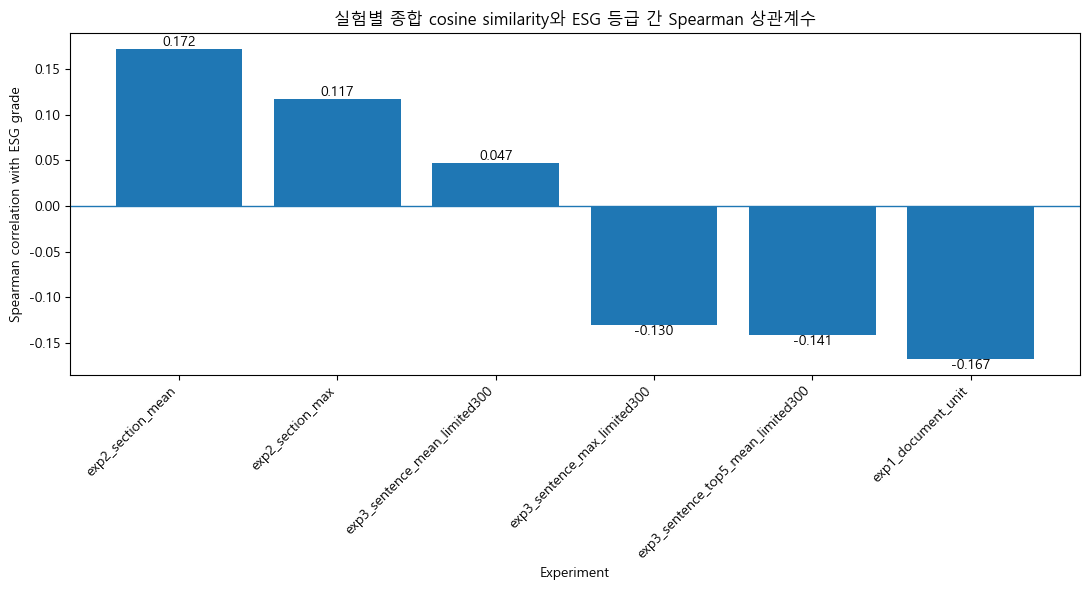

저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\plot_total_spearman_by_experiment.png


In [20]:
# ============================================================
# 11. 시각화 1: total score Spearman 상관계수
# ============================================================

total_corr_df = (
    spearman_df[spearman_df["score"] == "score_total"]
    .dropna(subset=["spearman_corr"])
    .sort_values("spearman_corr", ascending=False)
    .copy()
)

plt.figure(figsize=(11, 6))

plt.bar(
    total_corr_df["experiment"],
    total_corr_df["spearman_corr"],
)

plt.axhline(0, linewidth=1)

plt.xlabel("Experiment")
plt.ylabel("Spearman correlation with ESG grade")
plt.title("실험별 종합 cosine similarity와 ESG 등급 간 Spearman 상관계수")
plt.xticks(rotation=45, ha="right")

for i, v in enumerate(total_corr_df["spearman_corr"]):
    plt.text(i, v, f"{v:.3f}", ha="center", va="bottom" if v >= 0 else "top")

plt.tight_layout()

plot_path = OUTPUT_DIR / "plot_total_spearman_by_experiment.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("저장 완료:", plot_path)

# 12. 시각화 2: E/S/G 차원별 Spearman 상관계수 비교

- 각 실험 방식이 E, S, G 중 어느 차원에서 실제 ESG 등급과 더 잘 연결되는지 확인한다.
- 차원별로 상관계수가 높게 나타나는 방식을 비교할 수 있다.

score,score_E,score_G,score_S
experiment,,,
exp2_section_mean,0.157943,0.143705,0.100131
exp2_section_max,0.241464,0.045634,-0.001189
exp3_sentence_mean_limited300,-0.229086,0.074887,0.359234
exp3_sentence_max_limited300,-0.051101,-0.159594,0.012266
exp3_sentence_top5_mean_limited300,-0.058256,-0.139779,0.009297
exp1_document_unit,-0.077583,-0.223840,-0.037586


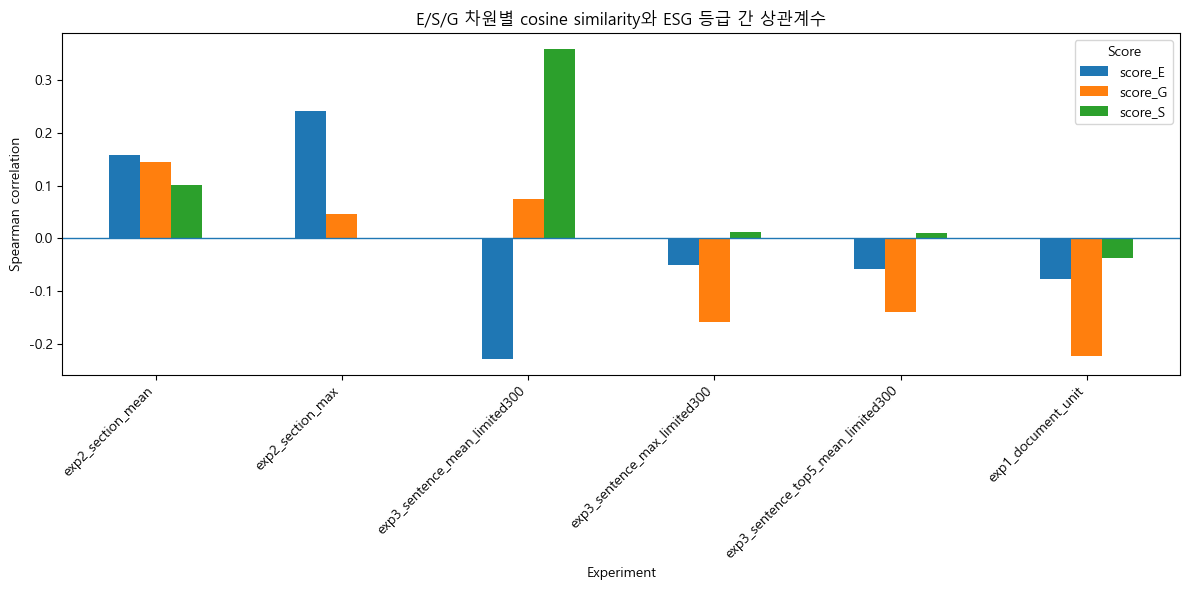

저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\plot_dimension_spearman_by_experiment.png


In [21]:
# ============================================================
# 12. 시각화 2: E/S/G 차원별 Spearman 상관계수 비교
# ============================================================

dim_corr_df = spearman_df[
    spearman_df["score"].isin(["score_E", "score_S", "score_G"])
].copy()

pivot_corr = dim_corr_df.pivot(
    index="experiment",
    columns="score",
    values="spearman_corr"
)

pivot_corr = pivot_corr.loc[
    total_corr_df["experiment"]
]

display(pivot_corr)

pivot_corr.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.axhline(0, linewidth=1)

plt.xlabel("Experiment")
plt.ylabel("Spearman correlation")
plt.title("E/S/G 차원별 cosine similarity와 ESG 등급 간 상관계수")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Score")
plt.tight_layout()

plot_path = OUTPUT_DIR / "plot_dimension_spearman_by_experiment.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("저장 완료:", plot_path)

# 13. 시각화 3: ESG 우수 그룹과 비우수 그룹 평균 차이

- ESG 우수 그룹과 비우수 그룹의 종합 similarity 평균 차이를 비교한다.
- 값이 클수록 ESG 우수 그룹에서 해당 similarity 점수가 더 높게 나타났다는 뜻이다.

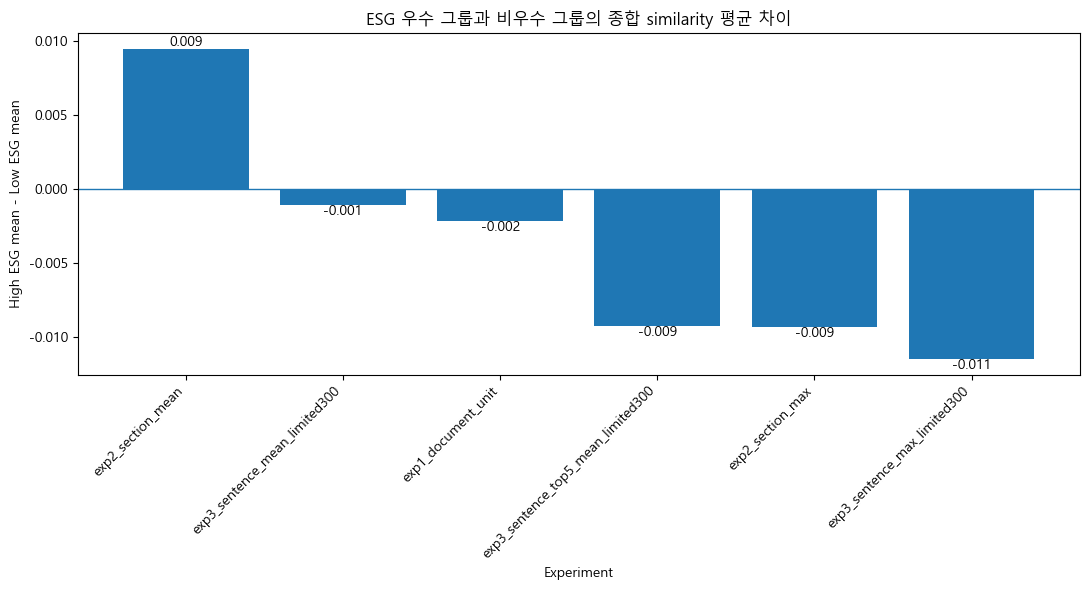

저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\plot_total_group_mean_diff.png


In [22]:
# ============================================================
# 13. 시각화 3: ESG 우수 그룹과 비우수 그룹 평균 차이
# ============================================================

total_group_df = (
    group_test_df[group_test_df["score"] == "score_total"]
    .sort_values("mean_diff", ascending=False)
    .copy()
)

plt.figure(figsize=(11, 6))

plt.bar(
    total_group_df["experiment"],
    total_group_df["mean_diff"],
)

plt.axhline(0, linewidth=1)

plt.xlabel("Experiment")
plt.ylabel("High ESG mean - Low ESG mean")
plt.title("ESG 우수 그룹과 비우수 그룹의 종합 similarity 평균 차이")
plt.xticks(rotation=45, ha="right")

for i, v in enumerate(total_group_df["mean_diff"]):
    plt.text(i, v, f"{v:.3f}", ha="center", va="bottom" if v >= 0 else "top")

plt.tight_layout()

plot_path = OUTPUT_DIR / "plot_total_group_mean_diff.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("저장 완료:", plot_path)

# 14. exp2 대표 섹션 및 exp3 대표 문장 저장

- exp2에서 가장 높은 similarity를 보인 섹션을 확인한다.
- exp3에서 가장 높은 similarity를 보인 문장을 확인한다.
- 정량 결과가 실제 ESG 문맥에 맞는지 해석할 때 사용한다.

In [23]:
# ============================================================
# 14. exp2 대표 섹션 및 exp3 대표 문장 저장
# ============================================================

# exp2 대표 섹션
exp2_best_section_path = OUTPUT_DIR / "exp2_best_sections.csv"

exp2_agg[
    [
        "analysis_unit",
        "stock_code",
        "company_name" if "company_name" in exp2_agg.columns else "fiscal_year",
        "fiscal_year",
        "esg_year",
        "esg_grade",
        "exp2_best_section",
        "exp2_best_section_total_score",
    ]
].to_csv(
    exp2_best_section_path,
    index=False,
    encoding="utf-8-sig"
)

print("exp2 대표 섹션 저장:", exp2_best_section_path)


# exp3 대표 문장
exp3_best_sentence_path = OUTPUT_DIR / "exp3_best_sentences.csv"

exp3_agg[
    [
        "analysis_unit",
        "stock_code",
        "company_name" if "company_name" in exp3_agg.columns else "fiscal_year",
        "fiscal_year",
        "esg_year",
        "esg_grade",
        "exp3_best_sentence_section",
        "exp3_best_sentence_total_score",
        "exp3_best_sentence",
    ]
].to_csv(
    exp3_best_sentence_path,
    index=False,
    encoding="utf-8-sig"
)

print("exp3 대표 문장 저장:", exp3_best_sentence_path)

display(exp3_agg[
    [
        "company_name" if "company_name" in exp3_agg.columns else "stock_code",
        "esg_grade",
        "exp3_best_sentence_section",
        "exp3_best_sentence_total_score",
        "exp3_best_sentence",
    ]
].head(10))

exp2 대표 섹션 저장: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\exp2_best_sections.csv
exp3 대표 문장 저장: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\exp3_best_sentences.csv


,company_name,esg_grade,exp3_best_sentence_section,exp3_best_sentence_total_score,exp3_best_sentence
0,동화약품,C,II. 사업의 내용,1.764269,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
1,동화약품,C,II. 사업의 내용,1.764269,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
2,경방,C,II. 사업의 내용,1.768437,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
3,경방,C,II. 사업의 내용,1.764269,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
4,경방,C,II. 사업의 내용,1.764269,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
5,유한양행,A,II. 사업의 내용,1.764269,회사의 내부회계관리제도는 (1) 회사 자산의 거래와 처분을 합리적인 수준으로 정확하...
6,하이트진로홀딩스,C,VIII. 임원 및 직원 등에 관한 사항,1.903882,"과징금 70억 6,500만원 재납부 2) 과태료 - 개인 : 과태료 3백만원 납부 ..."
7,성창기업지주,D,II. 사업의 내용,1.815317,(2) 자본위험관리 회사의 자본위험 관리 목적은 계속기업으로서 주주 및 이해당사자들...
8,DL,A,VIII. 임원 및 직원 등에 관한 사항,1.512407,준법지원인의 주요 활동내역 및 그 처리 결과 구분 활동일시 주요활동내용 결과 준법지...
9,일동홀딩스,A,II. 사업의 내용,1.806186,주요 활동내역 일시 빈도 주요내용 경영활동 전반에 대한 준법준수여부 점검 상시 공정...


# 15. 최종 결과 저장

- exp1, exp2, exp3 통합 비교 데이터 저장
- Spearman 상관분석 결과 저장
- 그룹 차이 검정 결과 저장
- 시각화 파일 저장

In [24]:
# ============================================================
# 15. 최종 결과 저장
# ============================================================

comparison_path = OUTPUT_DIR / "dense_embedding_all_experiment_scores.csv"

comparison_df.to_csv(
    comparison_path,
    index=False,
    encoding="utf-8-sig"
)

print("통합 점수 데이터 저장:", comparison_path)
print("Spearman 결과 저장:", spearman_path)
print("그룹 검정 결과 저장:", group_test_path)

display(comparison_df.head())

통합 점수 데이터 저장: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\dense_embedding_all_experiment_scores.csv
Spearman 결과 저장: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\dense_embedding_spearman_comparison.csv
그룹 검정 결과 저장: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\dense_embedding_compare\comparison_results\dense_embedding_group_test_comparison.csv


,experiment,unit_type,analysis_unit,stock_code,company_name,fiscal_year,esg_year,esg_grade,esg_grade_num,score_E,score_S,score_G,score_total,high_esg
0,exp1_document_unit,document,000020x2023,000020,동화약품,2023,2024,C,1,0.350940,0.349601,0.498880,1.199420,0
1,exp1_document_unit,document,000020x2024,000020,동화약품,2024,2025,C,1,0.372824,0.388960,0.503313,1.265097,0
2,exp1_document_unit,document,000050x2022,000050,경방,2022,2023,C,1,0.351881,0.342640,0.490117,1.184638,0
3,exp1_document_unit,document,000050x2023,000050,경방,2023,2024,C,1,0.326163,0.338822,0.537503,1.202488,0
4,exp1_document_unit,document,000050x2024,000050,경방,2024,2025,C,1,0.361480,0.397072,0.545335,1.303887,0
